# 1.0 — Initial Data Exploration

**Case**: Credit granting policy review for a Fintech client (Klavi).

**Goal of this notebook**: first contact with the raw data — schemas, keys, coverage, data quality, target definition — before any feature analysis or modeling.

**Inputs** (`data/raw/`):
- `profile_case_credit.parquet` — despite the name, holds **performance data**: `uuid`, `DATA`, `SAFRA` (vintage), `OVER30M2` (default flag: over 30 days past due in first 2 months), `STATUS`
- `transactions_case_credit.parquet` — despite the name, holds **application features**: Klavi scores, social class, employment status, region, income, betting-risk, financial capacity

**Questions to answer here**:
1. What is the grain of each table? Confirm the business key: `uuid` + application date (`DATA` in perf, `REFERENCIA` in feat)
2. How well do the two tables join (coverage / orphans)?
3. What does the target `OVER30M2` look like — overall rate and by `SAFRA` (vintage stability)?
4. Data quality: missingness, duplicates, suspicious values, dtypes to fix

In [1]:
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")
pd.set_option("display.max_columns", 50)

PROJECT_DIR = Path.cwd().parent
RAW_DIR = PROJECT_DIR / "data" / "raw"

PROFILE_PATH = RAW_DIR / "profile_case_credit.parquet" # performance data
TRANSACTIONS_PATH = RAW_DIR / "transactions_case_credit.parquet" # application features

## 1. Load raw data

In [2]:
perf = pd.read_parquet(PROFILE_PATH)      # performance / target table
feat = pd.read_parquet(TRANSACTIONS_PATH)  # features table

# drop leftover pandas index column if present
feat = feat.drop(columns=[c for c in feat.columns if c.startswith("__index_level")])

print(f"perf: {perf.shape[0]:,} rows x {perf.shape[1]} cols")
print(f"feat: {feat.shape[0]:,} rows x {feat.shape[1]} cols")

perf: 220,618 rows x 5 cols
feat: 371,596 rows x 10 cols


In [3]:
# dtypes as loaded: dates come as strings, SAFRA as float, risco_aposta as a 0-10 ordinal stored as float
print("perf:", dict(perf.dtypes.astype(str)))
print("feat:", dict(feat.dtypes.astype(str)))

# in-memory conversions (raw files stay untouched)
perf["DATA"] = pd.to_datetime(perf["DATA"])
perf["SAFRA"] = perf["SAFRA"].astype(int)
feat["REFERENCIA"] = pd.to_datetime(feat["REFERENCIA"])
feat["risco_aposta"] = feat["risco_aposta"].astype("Int64").astype("string")

perf: {'uuid': 'str', 'DATA': 'str', 'SAFRA': 'float64', 'OVER30M2': 'float64', 'STATUS': 'str'}
feat: {'uuid': 'str', 'REFERENCIA': 'str', 'score_klavi_1': 'float64', 'score_klavi_2': 'float64', 'classe_social': 'str', 'status_empregaticio': 'str', 'regiao': 'str', 'Renda': 'float64', 'risco_aposta': 'float64', 'Capacidade Financeira': 'float64'}


In [4]:
perf.head()

,uuid,DATA,SAFRA,OVER30M2,STATUS
0,d946dabe8351c29c3ca9db3c7005341b,2024-08-24,202408,0.0,Contratado
1,b9aa3d3552e2e21f92d34df2540de5c3,2024-09-02,202409,1.0,Contratado
2,ac5371c706da6f7a57c9b9593a8a5d04,2024-11-25,202411,0.0,Contratado
3,d44880bed90eaacb2fba3feead83ca16,2024-09-09,202409,0.0,Contratado
4,8ec0eefeda7ae58d5a98a2d59aca4bbb,2024-06-18,202406,0.0,Contratado


In [5]:
feat.head()

,uuid,REFERENCIA,score_klavi_1,score_klavi_2,classe_social,status_empregaticio,regiao,Renda,risco_aposta,Capacidade Financeira
0,7b0c9b36fe0f730f7c0d081534ff9a2b,2024-06-12,58.07,512.0,D/E,Desconhecido,Sudeste,1052.65,0,839.64
3,513b46119c7d33fc324f3c561905c159,2025-02-06,NaN,422.0,C,Desconhecido,Sudeste,NaN,<NA>,2213.37
7,0d7fed4a5b92cbae24e2b80e49fb0a4e,2025-06-13,NaN,607.0,C,Desconhecido,Sudeste,NaN,<NA>,587.04
8,c158eeca94b81f5f63cee1496dbea081,2024-07-30,NaN,NaN,C,Autônomo,Sudeste,NaN,<NA>,1961.59
9,97ebff4ac03d546fcb03040d1866bea0,2024-11-04,NaN,533.0,B,Desconhecido,Sudeste,NaN,<NA>,3585.16


In [6]:
# a single example: one application (uuid + DATA) with performance
perf.query("uuid == 'd946dabe8351c29c3ca9db3c7005341b'")

,uuid,DATA,SAFRA,OVER30M2,STATUS
0,d946dabe8351c29c3ca9db3c7005341b,2024-08-24,202408,0.0,Contratado


In [7]:
# the same uuid in feat: multiple snapshots, keyed by uuid + REFERENCIA
feat.query("uuid == 'd946dabe8351c29c3ca9db3c7005341b'")

,uuid,REFERENCIA,score_klavi_1,score_klavi_2,classe_social,status_empregaticio,regiao,Renda,risco_aposta,Capacidade Financeira
762710,d946dabe8351c29c3ca9db3c7005341b,2025-02-15,NaN,562.0,C,Formal,Sudeste,NaN,<NA>,1348.6
1189816,d946dabe8351c29c3ca9db3c7005341b,2024-08-24,NaN,552.0,C,Formal,Sudeste,NaN,<NA>,1348.6


**Key takeaway**: file names are misleading — `profile_*` holds **performance**, `transactions_*` holds **application features**. Dtypes normalized at load: `DATA`/`REFERENCIA` → datetime, `SAFRA` → int, `risco_aposta` (0–10 ordinal) → categorical string.

## 2. Grain and keys

`uuid` + application date (`DATA` in perf, `REFERENCIA` in feat) is the inferred business key — the check below validates that it is unique in both tables.

Notice in the example above: the user seems to have a single application granted (and therefore with performance `OVER30M2`).

In [8]:
for name, df in [("perf", perf), ("feat", feat)]:
    date_key = "DATA" if name == "perf" else "REFERENCIA"  
    n = len(df)
    n_uuid_date = len(df[["uuid", date_key]].copy().drop_duplicates())
    n_dup_rows = df.duplicated().sum()
    print(f"{name}: rows={n:,}  unique uuid;date_key={n_uuid_date:,}  fully-duplicated rows={n_dup_rows:,}")

perf: rows=220,618  unique uuid;date_key=220,618  fully-duplicated rows=0


feat: rows=371,596  unique uuid;date_key=371,596  fully-duplicated rows=0


In [9]:
# uuids repeating is expected under the composite key: repeat applications (perf) / multiple snapshots (feat)
dup_uuid_perf = perf[perf["uuid"].duplicated(keep=False)].sort_values("uuid")
dup_uuid_feat = feat[feat["uuid"].duplicated(keep=False)].sort_values("uuid")
print(f"perf rows with repeated uuid: {len(dup_uuid_perf):,}")
print(f"feat rows with repeated uuid: {len(dup_uuid_feat):,}")
dup_uuid_feat[:5]

perf rows with repeated uuid: 55,840
feat rows with repeated uuid: 333,361


,uuid,REFERENCIA,score_klavi_1,score_klavi_2,classe_social,status_empregaticio,regiao,Renda,risco_aposta,Capacidade Financeira
33864,000007d320ee2155609c8f68d640580e,2024-08-30,NaN,503.0,C,Autônomo,Centro-Oeste,NaN,<NA>,379.66
1088937,000007d320ee2155609c8f68d640580e,2025-04-14,NaN,519.0,C,Autônomo,Centro-Oeste,NaN,<NA>,379.66
1131442,000007d320ee2155609c8f68d640580e,2025-06-16,NaN,522.0,C,Autônomo,Centro-Oeste,NaN,<NA>,379.66
1152476,000007d320ee2155609c8f68d640580e,2024-09-02,NaN,503.0,C,Autônomo,Centro-Oeste,NaN,<NA>,379.66
1166447,000007d320ee2155609c8f68d640580e,2024-08-29,NaN,503.0,C,Autônomo,Centro-Oeste,NaN,<NA>,379.66


In [10]:
perf.query("uuid == '000007d320ee2155609c8f68d640580e'")

,uuid,DATA,SAFRA,OVER30M2,STATUS
42302,000007d320ee2155609c8f68d640580e,2024-08-29,202408,NaN,Aprovado


In [11]:
dup_uuid_perf.head(5)

,uuid,DATA,SAFRA,OVER30M2,STATUS
107916,00040a2ab502b7d35b578f41162c9dd9,2025-05-10,202505,NaN,Reprovado
171902,00040a2ab502b7d35b578f41162c9dd9,2024-08-08,202408,NaN,Reprovado
10706,000598ad1a06529e51d17114bc6fb76e,2025-04-09,202504,0.0,Contratado
16077,000598ad1a06529e51d17114bc6fb76e,2024-12-09,202412,0.0,Contratado
16638,000598ad1a06529e51d17114bc6fb76e,2025-04-22,202504,0.0,Contratado


In [12]:
feat.query("uuid == '00040a2ab502b7d35b578f41162c9dd9'")

,uuid,REFERENCIA,score_klavi_1,score_klavi_2,classe_social,status_empregaticio,regiao,Renda,risco_aposta,Capacidade Financeira


In [13]:
feat.query("uuid == '000598ad1a06529e51d17114bc6fb76e'")

,uuid,REFERENCIA,score_klavi_1,score_klavi_2,classe_social,status_empregaticio,regiao,Renda,risco_aposta,Capacidade Financeira


**Key takeaway**: the business key is `uuid` + application date (`DATA` in perf, `REFERENCIA` in feat) — unique in both tables. Repeated `uuid`s are repeat applications (perf) and multiple feature snapshots (feat), expected under this key.

## 3. Coverage — features available at decision time

One row per application (`uuid` + `DATA`), attaching the feature snapshot taken at the application date (`REFERENCIA` = `DATA`) via a simple left join — snapshots are application-triggered, so no future information can enter (equivalence with a point-in-time asof rule is verified in notebook 1.1). Coverage is then read where it matters: per (`STATUS`, performance availability), how many applications lack a snapshot / each feature.

In [14]:
# simple left join on uuid + application date: snapshots are application-triggered
# (REFERENCIA == DATA whenever present; equivalence with an asof rule verified in 1.1)
df = perf.merge(
    feat,
    left_on=["uuid", "DATA"], right_on=["uuid", "REFERENCIA"],
    how="left",
)

# missing counts per (STATUS, performance availability); REFERENCIA missing == no snapshot at decision time
feature_cols = [c for c in feat.columns if c != "uuid"]
cov = df.assign(PERFORMANCE=np.where(df["OVER30M2"].notna(), "with target", "no target"))
g = cov.groupby(["STATUS", "PERFORMANCE"])
coverage = (
    g.size().to_frame("n")
    .join(g[feature_cols].agg(lambda s: s.isna().sum()))
    .rename(columns={"REFERENCIA": "no_snapshot"})
)
coverage

,,n,no_snapshot,score_klavi_1,score_klavi_2,classe_social,status_empregaticio,regiao,Renda,risco_aposta,Capacidade Financeira
STATUS,PERFORMANCE,,,,,,,,,,
Aprovado,no target,77223,37129,73714,42227,37129,37129,37208,73714,73714,41352
Contratado,with target,24148,11706,23067,13059,11706,11706,11733,23067,23067,13140
Reprovado,no target,119247,57094,114003,63071,57094,57094,57190,114003,114003,66601


In [15]:
# same table as % of each row's applications (n)
coverage_pct = coverage.drop(columns="n").div(coverage["n"], axis=0).mul(100).round(1)
coverage_pct

,,no_snapshot,score_klavi_1,score_klavi_2,classe_social,status_empregaticio,regiao,Renda,risco_aposta,Capacidade Financeira
STATUS,PERFORMANCE,,,,,,,,,
Aprovado,no target,48.1,95.5,54.7,48.1,48.1,48.2,95.5,95.5,53.5
Contratado,with target,48.5,95.5,54.1,48.5,48.5,48.6,95.5,95.5,54.4
Reprovado,no target,47.9,95.6,52.9,47.9,47.9,48.0,95.6,95.6,55.9


**Key takeaway**: ~48% of applications have **no feature snapshot at decision time**, and the gap is uniform across `STATUS` (Aprovado 48.1%, Contratado 48.5%, Reprovado 47.9%) — availability does not differ by decision outcome. On the labeled `Contratado` sample even the broad variables are thin: `score_klavi_2` and `Capacidade Financeira` are missing for ~54% of applications; `score_klavi_1`/`Renda`/`risco_aposta` for ~95%.

## 4. Target: `OVER30M2`

Overall default rate, missing target rows, and rate by `SAFRA` (vintage) — a stable target across vintages is a precondition for pooling them in one model.

In [16]:
print(perf["OVER30M2"].value_counts(dropna=False))
print(f"\noverall default rate (non-missing): {perf['OVER30M2'].mean():.2%}")
print(f"missing target: {perf['OVER30M2'].isna().mean():.2%}")
print("\nSTATUS breakdown:")
print(perf["STATUS"].value_counts(dropna=False))

OVER30M2
NaN    196470
0.0     21660
1.0      2488
Name: count, dtype: int64

overall default rate (non-missing): 10.30%
missing target: 89.05%

STATUS breakdown:
STATUS
Reprovado     119247
Aprovado       77223
Contratado     24148
Name: count, dtype: int64


In [17]:
# how does STATUS relate to having a target? (e.g. rejected apps have no performance)
pd.crosstab(perf["STATUS"], perf["OVER30M2"].isna(), dropna=False)

OVER30M2,False,True
STATUS,,
Aprovado,0,77223
Contratado,24148,0
Reprovado,0,119247


**Key takeaway**: only `STATUS = Contratado` has performance (`OVER30M2`) — which makes sense: only contracted loans can be observed.

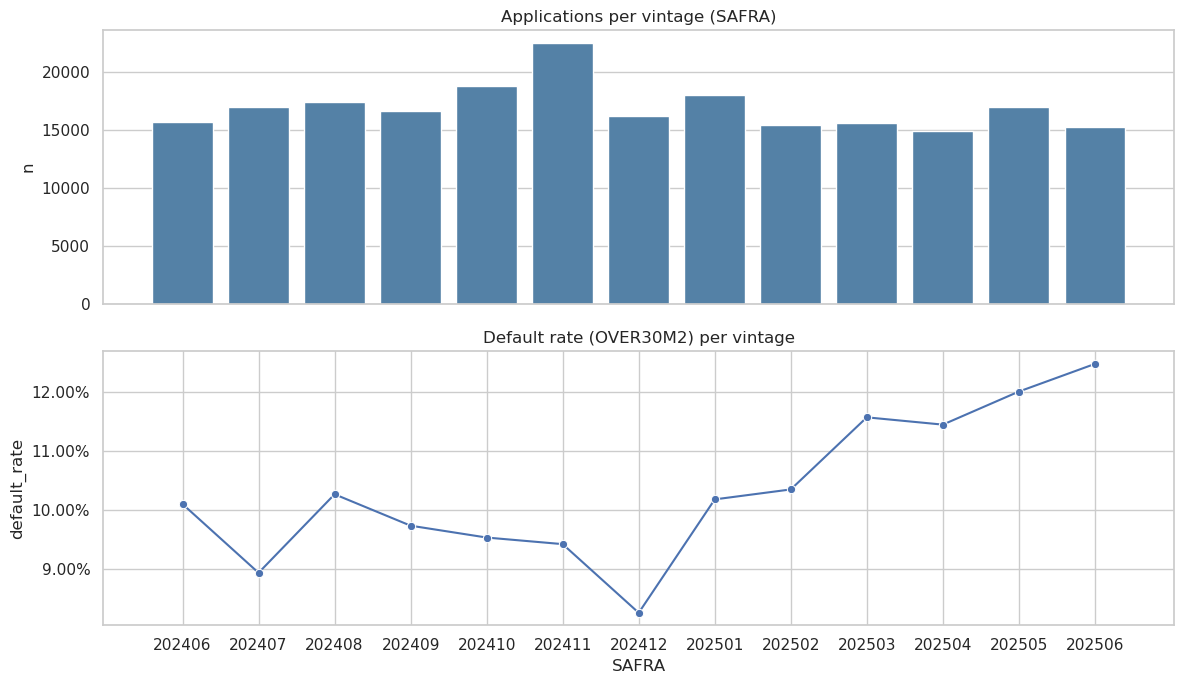

,SAFRA,n,default_rate
0,202406,15683,0.101005
1,202407,17011,0.089351
2,202408,17408,0.102667
3,202409,16678,0.097341
4,202410,18800,0.095330
5,202411,22498,0.094212
6,202412,16256,0.082569
7,202501,18049,0.101800
8,202502,15469,0.103488
9,202503,15607,0.115712


In [18]:
by_safra = (
    perf.groupby("SAFRA", dropna=False)
    .agg(n=("uuid", "size"), default_rate=("OVER30M2", "mean"))
    .reset_index()
    .sort_values("SAFRA")
)
# SAFRA as a string label: both subplots share one ordered categorical axis
# (numeric x would misalign barplot vs lineplot and add a fake 202413..202500 gap)
by_safra["SAFRA"] = by_safra["SAFRA"].astype(str)

fig, axes = plt.subplots(2, 1, figsize=(12, 7), sharex=True)
sns.barplot(data=by_safra, x="SAFRA", y="n", ax=axes[0], color="steelblue")
axes[0].set_title("Applications per vintage (SAFRA)")
sns.lineplot(data=by_safra, x="SAFRA", y="default_rate", ax=axes[1], marker="o")
axes[1].set_title("Default rate (OVER30M2) per vintage")
axes[1].yaxis.set_major_formatter(plt.matplotlib.ticker.PercentFormatter(1.0))
plt.tight_layout()
plt.show()

by_safra

**Key takeaway**: from 202501 onwards the default rate increases with a consistent slope — real deterioration or immature recent vintages.

## 5. Data quality — missingness and dtypes

In [19]:
def quality_report(df: pd.DataFrame) -> pd.DataFrame:
    return pd.DataFrame({
        "dtype": df.dtypes.astype(str),
        "n_missing": df.isna().sum(),
        "pct_missing": (df.isna().mean() * 100).round(2),
        "n_unique": df.nunique(),
    })

quality_report(perf)

,dtype,n_missing,pct_missing,n_unique
uuid,str,0,0.00,184009
DATA,datetime64[us],0,0.00,385
SAFRA,int64,0,0.00,13
OVER30M2,float64,196470,89.05,2
STATUS,str,0,0.00,3


In [20]:
quality_report(feat)

,dtype,n_missing,pct_missing,n_unique
uuid,str,0,0.00,96196
REFERENCIA,datetime64[us],0,0.00,385
score_klavi_1,float64,339319,91.31,1458
score_klavi_2,float64,40023,10.77,319
classe_social,str,0,0.00,4
status_empregaticio,str,0,0.00,5
regiao,str,583,0.16,5
Renda,float64,339319,91.31,4913
risco_aposta,string,339319,91.31,11
Capacidade Financeira,float64,46310,12.46,70497


In [21]:
# sentinel / invalid values — explicit counts
sk1 = feat["score_klavi_1"]
n_sent = (sk1 == -999999).sum()
print(f"score_klavi_1 == -999999: {n_sent:,} of {sk1.notna().sum():,} non-null ({n_sent / sk1.notna().sum():.1%})")

cf = feat["Capacidade Financeira"]
print(f"Capacidade Financeira < 0: {(cf < 0).sum():,} of {cf.notna().sum():,} non-null "
      f"(min={cf.min():,.0f}, p0.1={cf.quantile(0.001):,.0f}, p1={cf.quantile(0.01):,.0f})")

renda = feat["Renda"]
p99 = renda.quantile(0.99)
print(f"Renda > p99 ({p99:,.0f}): {(renda > p99).sum():,}  (max={renda.max():,.0f})")

# categorical columns: sentinel labels
for col in ["classe_social", "status_empregaticio", "regiao", "risco_aposta"]:
    n = (feat[col] == "-999999").sum()
    print(f"{col} == '-999999': {n:,}")

score_klavi_1 == -999999: 2,341 of 32,277 non-null (7.3%)
Capacidade Financeira < 0: 22,005 of 325,286 non-null (min=-1,088,145, p0.1=-12,414, p1=-2,454)
Renda > p99 (16,533): 323  (max=129,296)
classe_social == '-999999': 0
status_empregaticio == '-999999': 3,417
regiao == '-999999': 0
risco_aposta == '-999999': 0


In [22]:
# DATA was parsed to datetime at load — verify it is consistent with SAFRA: derived YYYYMM must match
derived_safra = perf["DATA"].dt.strftime("%Y%m").astype(int)
mismatch = perf[derived_safra != perf["SAFRA"]]
assert mismatch.empty, f"{len(mismatch):,} rows where SAFRA != YYYYMM(DATA)"
print(f"OK: SAFRA == YYYYMM(DATA) for all {len(perf):,} perf rows")

OK: SAFRA == YYYYMM(DATA) for all 220,618 perf rows


**Key takeaway**: `OVER30M2` is missing for 89.05% of perf rows (all non-`Contratado`). Sentinels are material and go to NaN (or an explicit category) in `1.1`: -999999 is **7.3% of non-null `score_klavi_1`**; `status_empregaticio` has **3,417 `'-999999'` labels**; `Capacidade Financeira` has **22,005 negatives** (min ≈ -1.09M). `Renda` has a thin extreme tail (323 rows above p99 ≈ 16.5k). `SAFRA` is fully consistent with YYYYMM(`DATA`) — it can always be re-derived.

## 6. Feature distributions

### 6.1 Numeric features

In [23]:
num_cols = feat.select_dtypes(include="number").columns.tolist()
feat[num_cols].describe().T

,count,mean,std,min,25%,50%,75%,max
score_klavi_1,32277.0,-72475.672167,259379.346501,-999999.00,40.34,57.25,68.19,100.00
score_klavi_2,331573.0,520.963981,60.696365,345.00,481.00,524.00,566.00,663.00
Renda,32277.0,2850.452457,3600.016877,317.28,1321.57,2066.94,3057.77,129296.19
Capacidade Financeira,325286.0,1925.910835,5038.807631,-1088144.71,803.83,1470.81,2361.59,120795.85


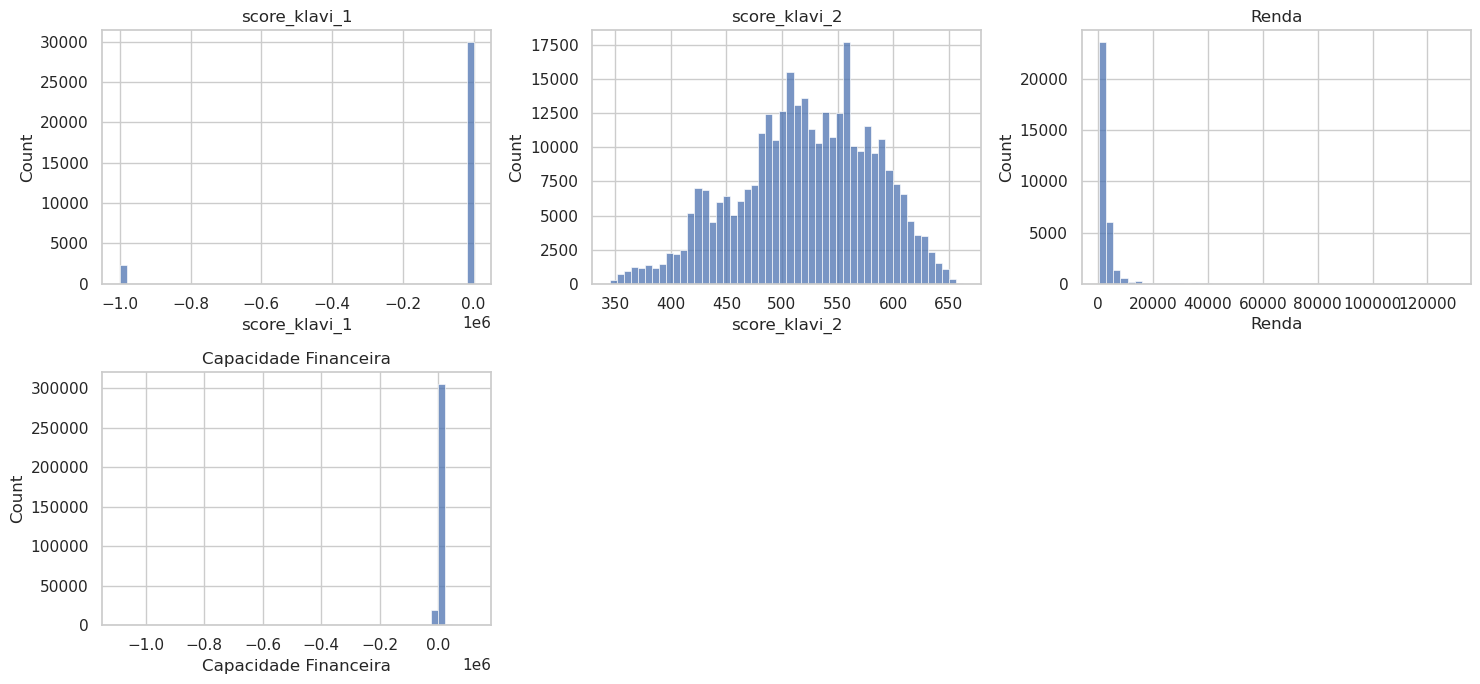

In [24]:
fig, axes = plt.subplots(2, 3, figsize=(15, 7))
for ax, col in zip(axes.flat, num_cols):
    sns.histplot(feat[col].dropna(), bins=50, ax=ax)
    ax.set_title(col)
for ax in axes.flat[len(num_cols):]:
    ax.set_visible(False)
plt.tight_layout()
plt.show()

### 6.2 Categorical features

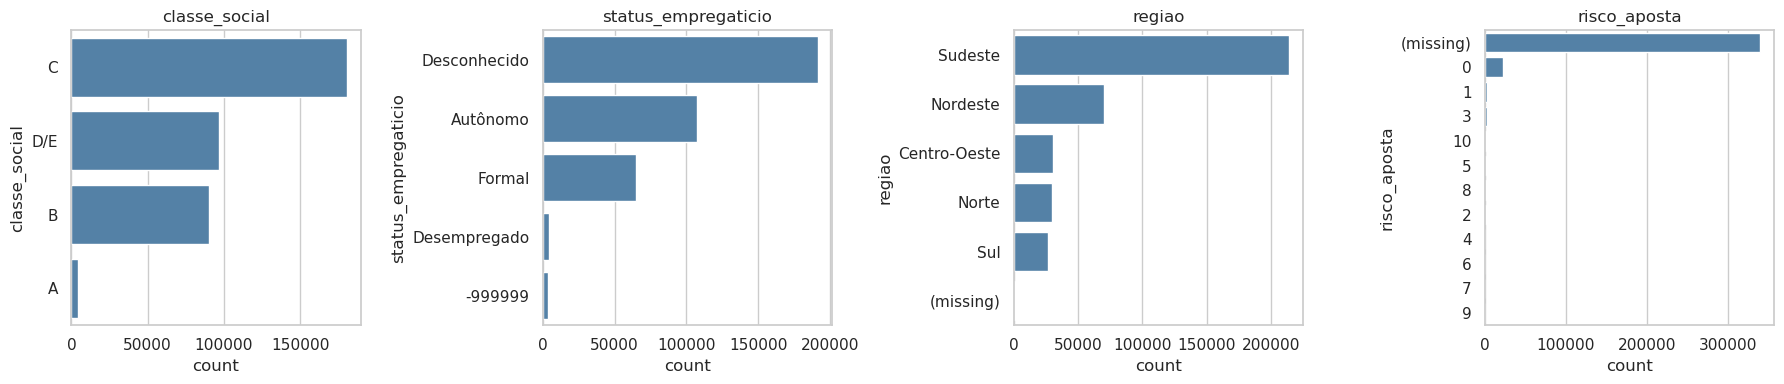

In [25]:
cat_cols = ["classe_social", "status_empregaticio", "regiao", "risco_aposta"]
feat_plot = feat[cat_cols].fillna("(missing)")
fig, axes = plt.subplots(1, len(cat_cols), figsize=(18, 4))
for ax, col in zip(axes, cat_cols):
    order = feat_plot[col].value_counts().index
    sns.countplot(data=feat_plot, y=col, order=order, ax=ax, color="steelblue")
    ax.set_title(col)
plt.tight_layout()
plt.show()

**Key takeaway**: `score_klavi_2` is well-behaved (bell-shaped, ~345–663); `score_klavi_1` is unreadable until the sentinel is removed (real range ~0–100); `Renda` and `Capacidade Financeira` are heavily right-skewed with extreme tails. Categoricals concentrate in C / Desconhecido / Sudeste; `risco_aposta` is mostly 0 when present.

## 7. First look at features vs target

Uses the application-date merged table `df` built in section 3; the labeled sample is the `Contratado` subset. Proper feature analysis (IV/WoE, correlations, leakage checks) goes in a later notebook.

In [26]:
labeled = df[df["OVER30M2"].notna()].copy()
print(f"applications: {len(df):,}   with snapshot: {df['REFERENCIA'].notna().sum():,}   with target: {len(labeled):,}")

applications: 220,618   with snapshot: 114,689   with target: 24,148


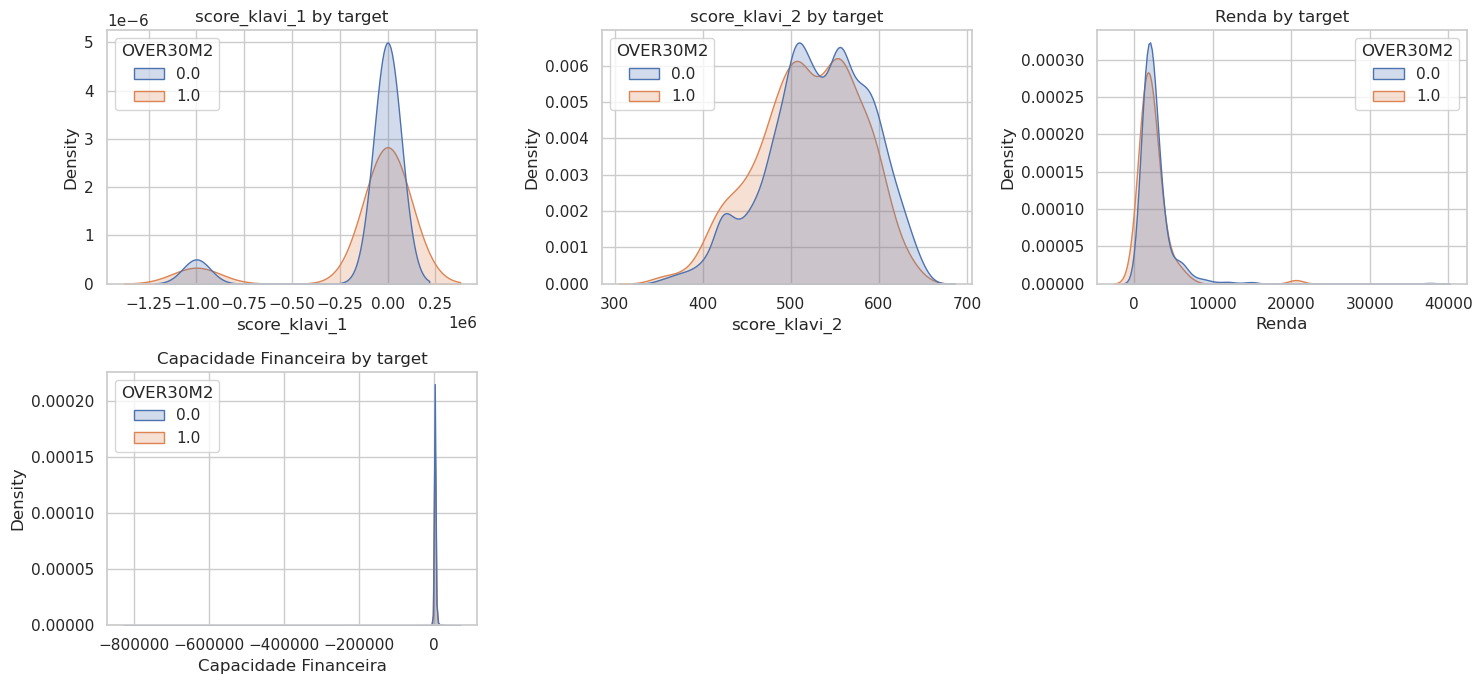

In [27]:
fig, axes = plt.subplots(2, 3, figsize=(15, 7))
for ax, col in zip(axes.flat, num_cols):
    sns.kdeplot(data=labeled, x=col, hue="OVER30M2", common_norm=False, fill=True, ax=ax)
    ax.set_title(f"{col} by target")
for ax in axes.flat[len(num_cols):]:
    ax.set_visible(False)
plt.tight_layout()
plt.show()

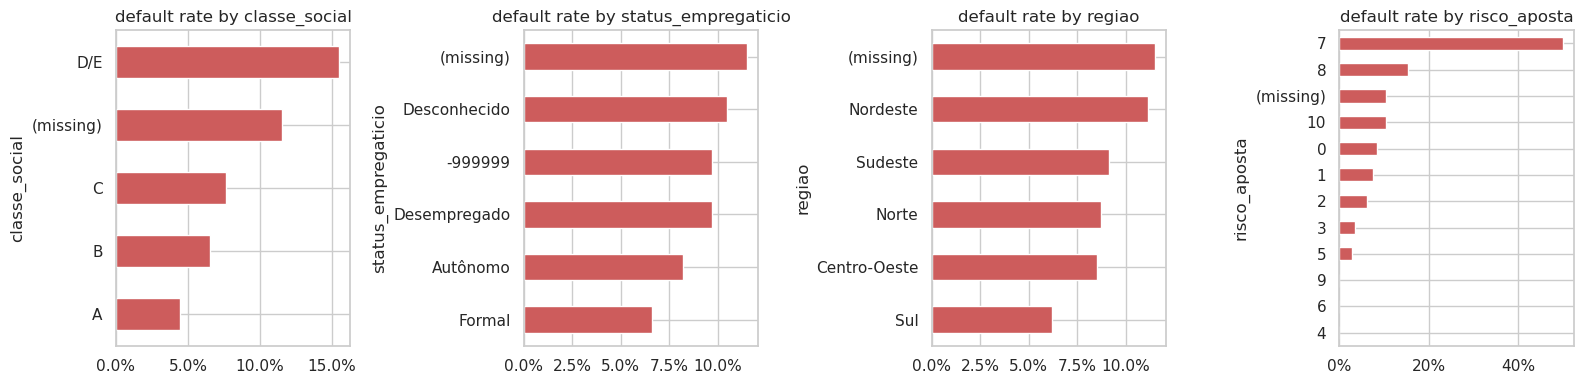

In [28]:
fig, axes = plt.subplots(1, len(cat_cols), figsize=(16, 4))
for ax, col in zip(axes, cat_cols):
    rate = (
        labeled.assign(**{col: labeled[col].fillna("(missing)")})
        .groupby(col)["OVER30M2"].mean().sort_values()
    )
    rate.plot.barh(ax=ax, color="indianred")
    ax.set_title(f"default rate by {col}")
    ax.xaxis.set_major_formatter(plt.matplotlib.ticker.PercentFormatter(1.0))
plt.tight_layout()
plt.show()

**Key takeaway**: categorical features look like strong predictors, while numeric features show a subtler separation — application scores might deepen the separation within groups such as `classe_social`. To be verified carefully (IV/WoE in phase 2).

## 8. Key takeaways & general findings

**Key takeaways per section**

1. **§1 Load** — file names are misleading (`profile_*` = performance, `transactions_*` = application features); dtypes normalized at load: `DATA`/`REFERENCIA` → datetime, `SAFRA` → int, `risco_aposta` (0–10 ordinal) → categorical string.
2. **§2 Grain** — the business key is `uuid` + application date (`DATA` in perf, `REFERENCIA` in feat), unique in both tables (perf: 220,618 rows / 184,009 uuids — repeat applications; feat: 371,596 rows / 96,196 uuids — multiple snapshots per person).
3. **§3 Coverage** — only 114,689 of 220,618 applications (52.0%) have a feature snapshot at decision time (snapshots are application-triggered: `REFERENCIA` = `DATA` whenever present, so a simple left join on `uuid` + application date suffices), and the gap is uniform across `STATUS` (Aprovado 48.1%, Contratado 48.5%, Reprovado 47.9%). On the labeled `Contratado` sample, `score_klavi_2` / `Capacidade Financeira` are missing for ~54% and `score_klavi_1`/`Renda`/`risco_aposta` for ~95%.
4. **§4 Target** — `OVER30M2` exists only for `STATUS = Contratado` (24,148 rows; 10.30% default rate); from 202501 onwards the default rate rises with a consistent slope, from ~8–10% (2024 vintages) to ~12.5% (202506) — real deterioration or immature recent vintages.
5. **§5 Quality** — sentinels are material: -999999 is 7.3% of non-null `score_klavi_1`; `status_empregaticio` has 3,417 `'-999999'` labels; `Capacidade Financeira` has 22,005 negatives (min ≈ -1.09M); `Renda` has a thin extreme tail (323 rows above p99 ≈ 16.5k). `SAFRA` is fully consistent with YYYYMM(`DATA`) — it can always be re-derived.
6. **§6 Distributions** — `score_klavi_2` is well-behaved (bell-shaped, ~345–663); `score_klavi_1` is unreadable until the sentinel is removed (real range ~0–100); `Renda` and `Capacidade Financeira` are heavily right-skewed. Categoricals concentrate in C / Desconhecido / Sudeste; `risco_aposta` is mostly 0 when present.
7. **§7 Signal** — categorical features look like strong predictors, while numeric features show a subtler separation; to be verified carefully (IV/WoE in phase 2).

**General findings**

- **Selection bias**: performance is observed only for contracted loans — any model trained on `Contratado` will not directly generalize to the through-the-door population (`Aprovado` 77k and `Reprovado` 119k are unlabeled) — a reject-inference caveat to carry through the analysis.
- **Structured missingness splits the variables into two tiers**: broad-coverage (`score_klavi_2` 10.8% missing, `Capacidade Financeira` 12.5%) vs narrow-coverage (`score_klavi_1`/`Renda`/`risco_aposta` jointly missing in 91.3% of feature rows — likely present only where open-finance/transactional data was shared). This split is central to policy practicality.
- **Notebook `1.1` must** re-apply the dtype casts and clean sentinels → NaN (or an explicit category) when building the interim one-row-per-application table.
